# Generate app data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from slabguide import Slab, Propagator, real_contour, ThreeJSMeshSaver, Plot3D

plt.style.use('dark_background')

In [2]:
A = Slab(scale=1e-5, Ts=[6.5, 1, 6, 1, 6.5],  ns=[1, 1.44, 1, 1.44, 1],
                 xrefs=[325, 200, 500, 200, 325], wl=5.83e-06)

B = Slab(scale=1e-5, Ts=[6.5, 1, 6, 1, 6.5],  ns=[1, 1.44, 1, 1.44, 1],
                 xrefs=[325, 200, 500, 200, 325], wl=6.90764471839393e-06)

In [3]:
half_width = 1
shift = .5
amplitude = 1

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

def quadratic_piecewise2d(x, zs=None, wavenumber=A.K0):
    fx = quadratic_piecewise(x)
    fz = np.exp(1j * wavenumber * zs)
    return np.outer(fz, fx)

f0 = quadratic_piecewise
F0 = quadratic_piecewise2d

In [4]:
P = Propagator(A, f0=f0, window=[Lx, Rx], calculate_guided_field=False)

In [81]:
Np = 60
Lz = .001
Rz = 1
P.add_contour(real_contour(Lz, Rz, Np))

In [86]:
Np = 350
Lz = 1
Rz = A.Z_evanescent

P.add_contour(real_contour(Lz, Rz, Np))

In [87]:
P.add_contour(real_contour(.515, .525, 20))
P.add_contour(real_contour(1.02, 1.06, 30))
P.add_contour(real_contour(1.53, 1.58, 20))
P.add_contour(real_contour(2.05, 2.1, 20))

Contour already exists.


In [88]:
Np = 100
Lz = A.Z_evanescent
Rz = 30

P.add_contour(real_contour(Lz, Rz, Np))

Contour already exists.


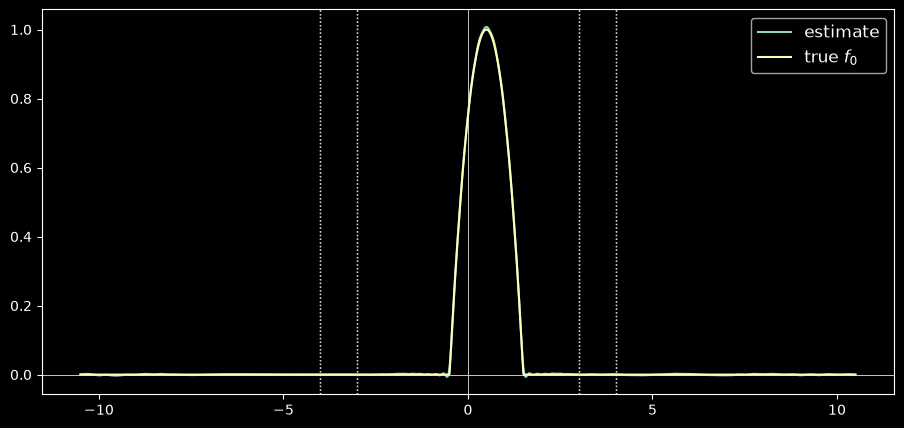

In [89]:
A.plot_field_1d(P, label='estimate') 
A.add_1d_plot(f0, label='true $f_0$');
plt.show();

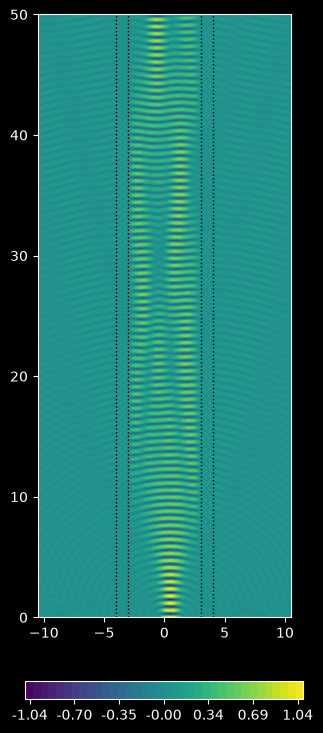

In [123]:
A.plot_field_2d(P, zmax=50, zref=50*20, xstride=8);

In [90]:
Plot3D(P, xstride=8);

<slabguide.plotting.Plot3D.Plot3D.<locals>.HelloWidget object at 0x7a2f02b87f20>

In [91]:
Q = Propagator(B, f0=f0, window=[Lx, Rx], calculate_guided_field=False)

In [107]:
Lz = .001
Rz = B.Z_evanescent
Np = 150

Q.add_contour(real_contour(Lz, Rz, Np))

In [116]:
Lz = B.Z_evanescent
Rz = 30
Np = 100

Q.add_contour(real_contour(Lz, Rz, Np))

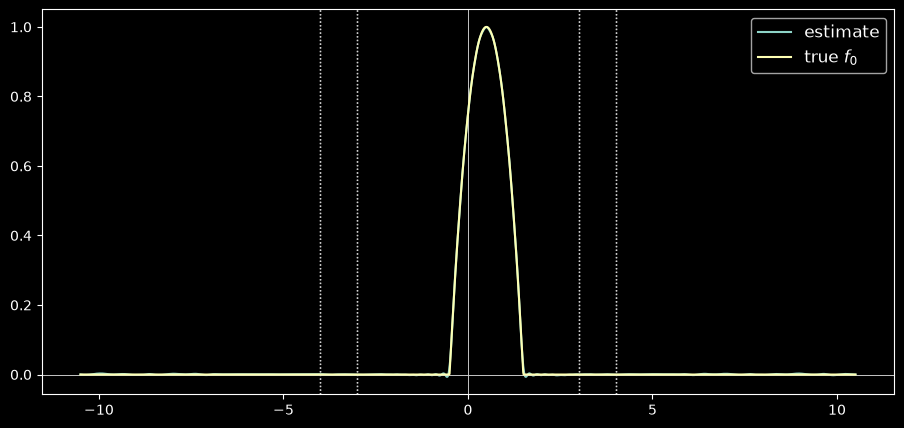

In [117]:
B.plot_field_1d(Q, label='estimate') 
B.add_1d_plot(f0, label='true $f_0$');
plt.show();

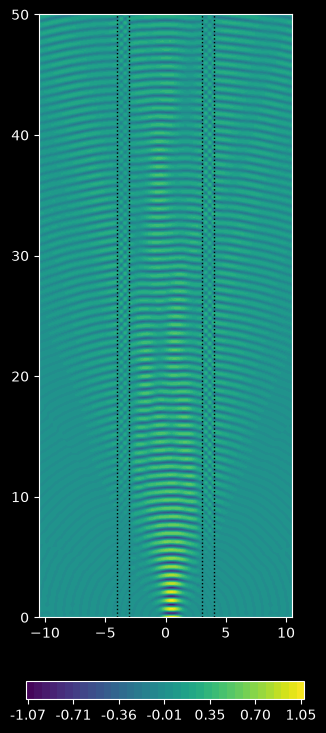

In [124]:
A.plot_field_2d(Q, zmax=50, zref=50*20, xstride=8);

In [118]:
Plot3D(Q, xstride=8);

<slabguide.plotting.Plot3D.Plot3D.<locals>.HelloWidget object at 0x7a2efe8e0320>

In [136]:
xs = A.all_Xs[::8]
ys = np.linspace(0, 50, int(50*40))
ymin, ymax = np.min(ys), np.max(ys)

Xs, Ys = np.meshgrid(xs, ys)
MS = ThreeJSMeshSaver(Xs, Ys)

trigs = MS.trig_indices
basepts = MS.base_vertices

Props = [P, Q]

In [137]:
gs = np.array([Prop.Guided(xs,ys) for Prop in Props])

In [139]:
ps = np.array([Prop.Propagating(xs, ys) for Prop in Props])

In [138]:
evs = np.array([Prop.Evanescent(xs, ys) for Prop in Props])

In [140]:
f0s = np.array(Props[0].f0(xs), dtype=np.float32)
Nmesh = np.array(len(Props), dtype=np.uint32)
ns = np.array(A.ns, dtype=np.float32)

Rhos = A.Rhos

In [141]:
prefix='/home/pv/local/website/visualizations/hollow_core/data/'

In [142]:
MS.save_trig_indices_as_json(prefix + 'trig_indices')
MS.save_base_vertices_as_json(prefix + 'base_vertices')


In [143]:
MS.save_values_as_json(prefix + 'f0s', f0s)
MS.save_values_as_json(prefix + 'x0s', xs)
MS.save_values_as_json(prefix + 'y0s', ys)
MS.save_values_as_json(prefix + 'Rhos', Rhos)


In [144]:
MS.save_heights_as_json_not_flat_complex(prefix + 'guided', gs, reduce_dims=False)


In [145]:
MS.save_heights_as_json_not_flat_complex(prefix + 'propagating', ps, reduce_dims=False)


In [146]:
MS.save_heights_as_json_not_flat_complex(prefix + 'evanescent', evs, reduce_dims=False)


Input field data

In [147]:
xs = A.all_Xs[::8]
input_ys = np.linspace(-5, 0, int(5*40))
inXs, inYs = np.meshgrid(xs, input_ys)
inMS = ThreeJSMeshSaver(inXs, inYs)
inMS.save_trig_indices_as_json(prefix + 'trig_indices_input')
inMS.save_base_vertices_as_json(prefix + 'base_vertices_input')
inMS.save_values_as_json(prefix + 'in_y0s', input_ys)

In [148]:
ins = F0(xs, input_ys)
inMS.save_heights_as_json(prefix + 'input_heights', ins)